In [ ]:
import os
import torch
import torchaudio
import torchaudio.transforms as T
import soundfile as sf
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Pre-initialize transforms directly on GPU VRAM
mfcc_transform = T.MFCC(
    sample_rate=16000,
    n_mfcc=13,
    melkwargs={"n_fft": 512, "n_mels": 40, "hop_length": 160}
).to(device)

spectral_centroid_transform = T.SpectralCentroid(
    sample_rate=16000,
    n_fft=512,
    hop_length=160
).to(device)

def extract_features(fpath, sr=16000):
    try:
        # Fast direct PCM read
        waveform, orig_sr = sf.read(fpath, dtype='float32')
        if waveform.ndim > 1:
            waveform = np.mean(waveform, axis=1)
        
        t_wave = torch.from_numpy(waveform).to(device)
        if orig_sr != sr:
            t_wave = torchaudio.functional.resample(t_wave, orig_sr, sr)
    except Exception:
        return None

    # Fast energy trim (20 dB threshold)
    mag = torch.abs(t_wave)
    if mag.numel() < 512:
        return None
    threshold = mag.max() * 0.1  # 20 dB = 0.1 amplitude
    mask = mag >= threshold
    if not mask.any():
        return None
    indices = torch.where(mask)[0]
    t_wave = t_wave[indices[0]:indices[-1] + 1]
    if t_wave.numel() < 512:
        return None

    with torch.no_grad():
        # MFCC & Delta (13, T)
        mfcc = mfcc_transform(t_wave.unsqueeze(0)).squeeze(0)
        delta1 = torchaudio.functional.compute_deltas(mfcc)

        # Zero Crossing Rate (frame_length=400, hop_length=160)
        unfolded = t_wave.unfold(0, 400, 160)
        signs = torch.sign(unfolded)
        zcr = (torch.abs(signs[:, 1:] - signs[:, :-1]) > 0).float().mean(dim=1)

        # RMS (frame_length=400, hop_length=160)
        rms = torch.sqrt(torch.mean(unfolded ** 2, dim=1) + 1e-8)

        # Spectral Centroid
        centroid = spectral_centroid_transform(t_wave.unsqueeze(0)).squeeze(0)

        # Spectral Rolloff 
        window = torch.hann_window(512, device=device)
        stft = torch.stft(t_wave, n_fft=512, hop_length=160, window=window, return_complex=True)
        spec_mag = torch.abs(stft)
        cumulative_energy = torch.cumsum(spec_mag, dim=0)
        total_energy = cumulative_energy[-1:, :]
        rolloff_idx = (cumulative_energy >= 0.85 * total_energy).int().argmax(dim=0).float()
        rolloff = rolloff_idx * (float(sr) / 512.0)

        # Aggregate statistics (mean and std) into 60-dimensional vector
        feats = torch.cat([
            mfcc.mean(dim=1), mfcc.std(dim=1),                  
            delta1.mean(dim=1), delta1.std(dim=1),              
            zcr.mean().unsqueeze(0), zcr.std().unsqueeze(0),    
            rms.mean().unsqueeze(0), rms.std().unsqueeze(0),    
            centroid.mean().unsqueeze(0), centroid.std().unsqueeze(0),  
            rolloff.mean().unsqueeze(0), rolloff.std().unsqueeze(0),    
        ]).cpu().numpy()

    return feats


Using device: cuda


In [10]:
import os
import glob
import pandas as pd
from tqdm import tqdm

dataset_path = "/content/dataset/50_speakers_audio_data"
audio_files = glob.glob(dataset_path + "/**/*.wav", recursive=True)

data = []
print(f"Extracting features from {len(audio_files)} files on {device}...")

for fpath in tqdm(audio_files):
    feats = extract_features(fpath)
    if feats is not None:
        speaker = os.path.basename(os.path.dirname(fpath))
        data.append([speaker] + feats.tolist())

columns = ["speaker"] + [f"f{i}" for i in range(60)]
df = pd.DataFrame(data, columns=columns)
df.to_csv("features.csv", index=False)

print(f"\nExtracted DataFrame Shape: {df.shape}")


Extracting features from 2511 files on cuda...


100%|██████████| 2511/2511 [00:35<00:00, 71.28it/s] 



Extracted DataFrame Shape: (2510, 61)


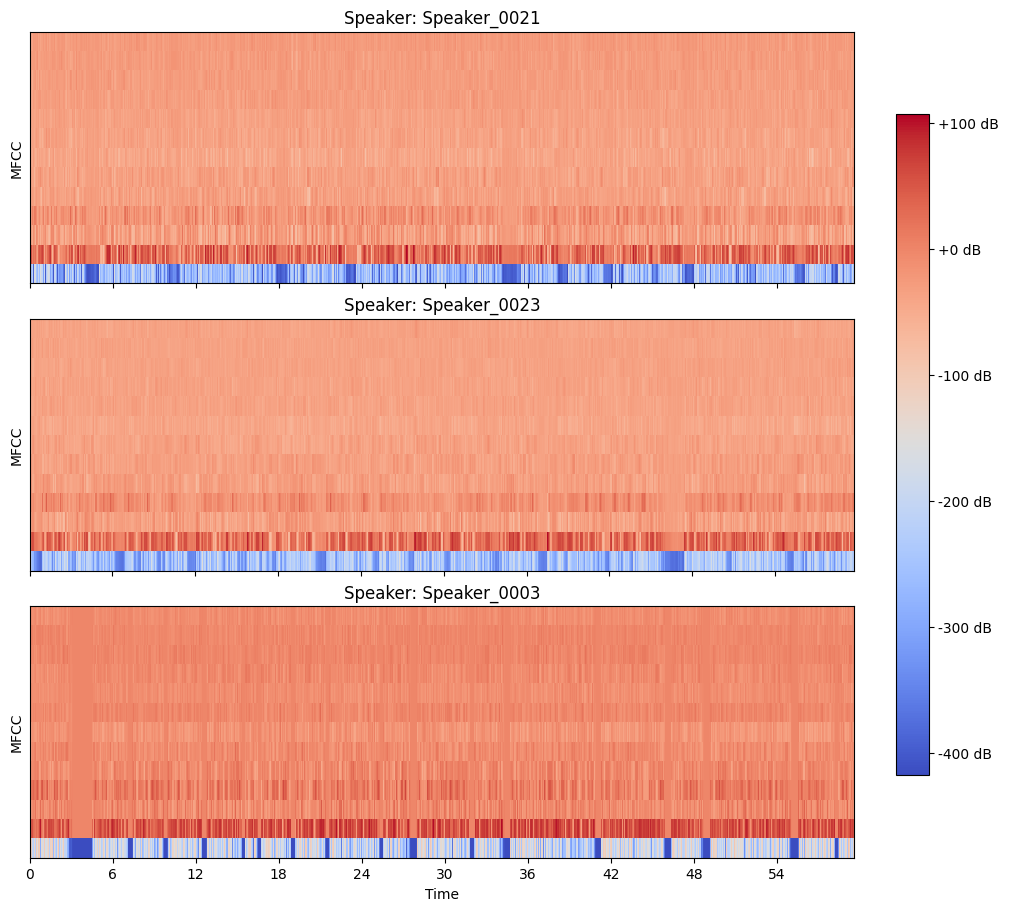

In [11]:
import matplotlib.pyplot as plt
import librosa.display

sample_paths = np.random.choice(audio_files, size=3, replace=False)
fig, axes = plt.subplots(3, 1, figsize=(10, 9), constrained_layout=True)

for ax, fpath in zip(axes, sample_paths):
    speaker = os.path.basename(os.path.dirname(fpath))
    y, sr = sf.read(fpath, dtype='float32')
    if y.ndim > 1:
        y = np.mean(y, axis=1)
    if sr != 16000:
        y = librosa.resample(y, orig_sr=sr, target_sr=16000)
        sr = 16000
    y, _ = librosa.effects.trim(y, top_db=20)

    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_fft=512, hop_length=160, n_mfcc=13, n_mels=40)
    img = librosa.display.specshow(mfcc, x_axis="time", sr=sr, hop_length=160, ax=ax, cmap="coolwarm")
    ax.set_title(f"Speaker: {speaker}")
    ax.set_ylabel("MFCC")
    ax.label_outer()

fig.colorbar(img, ax=axes, format="%+2.0f dB", shrink=0.8)
plt.show()
